In [3]:
import os, random, time, json, itertools, warnings, shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, roc_auc_score, roc_curve, classification_report)
from sklearn.svm import SVC
from scipy.stats import binomtest

import xgboost as xgb

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, mixed_precision

from skimage import io, transform
from skimage.color import rgb2gray
from skimage.feature import hog, local_binary_pattern
from joblib import Parallel, delayed

print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__)
print("GPUs:", tf.config.list_physical_devices('GPU'))

2026-11-01 12:54:42.142171: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1793537682.277599      40 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1793537682.317629      40 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


TensorFlow: 2.18.0 | Keras: 3.8.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [4]:
# ======================= CONFIG =======================
DATASET_DIR = "/kaggle/input/glaucomadataset/Glaucoma_Dataset2"   # contains glaucoma/ and normal/
OUTPUT_DIR  = "glaucoma_outputs_final"
os.makedirs(OUTPUT_DIR, exist_ok=True)

SEED = 42
keras.utils.set_random_seed(SEED)      # seeds python, numpy and TF
os.environ["PYTHONHASHSEED"] = str(SEED)

CLASSES = ['normal', 'glaucoma']       # label 0 = normal, 1 = glaucoma (positive class)
IMG_SIZE   = 224
BATCH_SIZE = 32
WARMUP_EPOCHS   = 10
FINETUNE_EPOCHS = 30
LR_WARMUP   = 1e-3
LR_FINETUNE = 1e-4
RESIZE_ML   = 128                      # image size for handcrafted features
USE_MIXED_PRECISION = True
N_BOOT   = 1000                        # bootstrap resamples for 95% CIs
N_TIMING = 100                         # test images used for latency measurement

In [5]:
IMG_EXT = {'.png', '.jpg', '.jpeg', '.tif', '.tiff', '.bmp'}
records = []
for class_idx, class_name in enumerate(CLASSES):
    folder = Path(DATASET_DIR) / class_name
    files = sorted(p for p in folder.iterdir() if p.suffix.lower() in IMG_EXT)   # sorted -> reproducible split
    print(f"Found {len(files)} images for class: {class_name}")
    records += [{"filepath": str(p), "class_name": class_name, "label": class_idx} for p in files]

df = pd.DataFrame(records)
print("Total dataset shape:", df.shape)
print(df['class_name'].value_counts())

Found 3000 images for class: normal
Found 3000 images for class: glaucoma
Total dataset shape: (6000, 3)
class_name
normal      3000
glaucoma    3000
Name: count, dtype: int64


In [6]:
# Exact-duplicate check (same file content). Duplicates that end up in both train and test inflate results.
import hashlib
def file_md5(p):
    with open(p, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

df["md5"] = Parallel(n_jobs=-1)(delayed(file_md5)(p) for p in df["filepath"])
dup_groups = df.groupby("md5").agg(n=("filepath", "size"), n_labels=("label", "nunique"))
n_dup_files   = int((df["md5"].duplicated(keep="first")).sum())
n_conflicting = int((dup_groups.n_labels > 1).sum())
print(f"Exact duplicate files (extra copies): {n_dup_files}")
print(f"Duplicate groups with CONFLICTING labels: {n_conflicting}")

REMOVE_DUPLICATES = True
N_IMAGES_BEFORE_DEDUP = len(df)
if REMOVE_DUPLICATES and n_dup_files > 0:
    conflicting = dup_groups.index[dup_groups.n_labels > 1]
    df = df[~df["md5"].isin(conflicting)]                 # drop images whose copies carry different labels
    df = df.drop_duplicates("md5", keep="first").reset_index(drop=True)
    print("After removing duplicates:", df.shape, df['class_name'].value_counts().to_dict())
N_DUPLICATES_REMOVED = N_IMAGES_BEFORE_DEDUP - len(df)

Exact duplicate files (extra copies): 0
Duplicate groups with CONFLICTING labels: 0


In [7]:
# Stratified 80 / 10 / 10 split -- identical subsets for ALL models
train_df, temp_df = train_test_split(df, test_size=0.2, stratify=df['label'], random_state=SEED)
val_df, test_df   = train_test_split(temp_df, test_size=0.5, stratify=temp_df['label'], random_state=SEED)
train_df, val_df, test_df = [d.reset_index(drop=True) for d in (train_df, val_df, test_df)]

for n, d in [("Train", train_df), ("Val", val_df), ("Test", test_df)]:
    print(f"{n:5s}: {d.shape}  {d['class_name'].value_counts().to_dict()}")
    d.to_csv(os.path.join(OUTPUT_DIR, f"{n.lower()}_paths.csv"), index=False)

y_train = train_df['label'].values
y_val   = val_df['label'].values
y_test  = test_df['label'].values

Train: (4800, 4)  {'normal': 2400, 'glaucoma': 2400}
Val  : (600, 4)  {'glaucoma': 300, 'normal': 300}
Test : (600, 4)  {'glaucoma': 300, 'normal': 300}


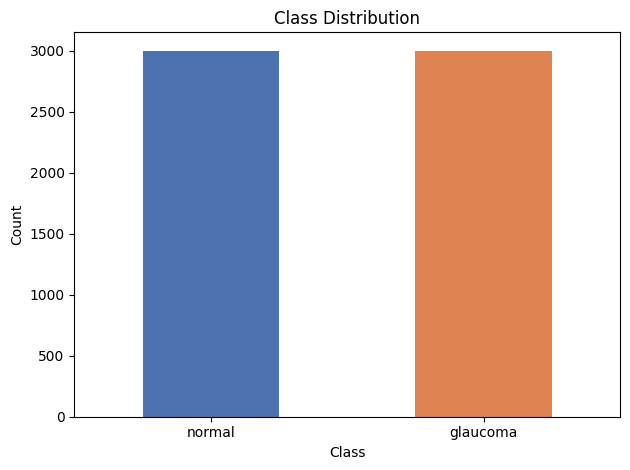

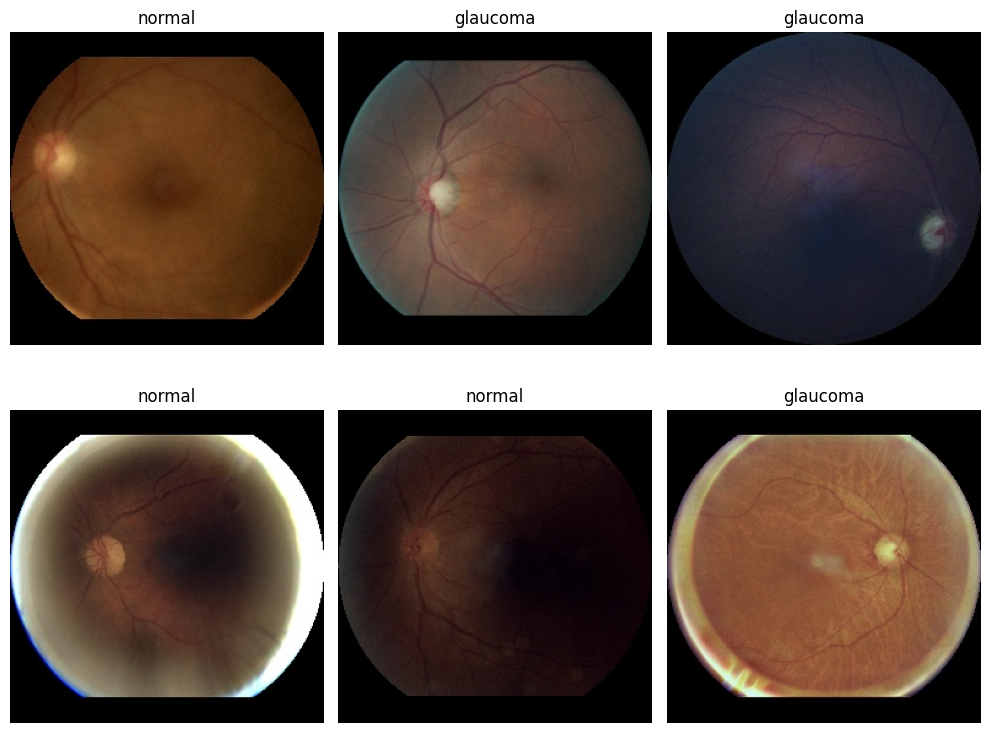

In [8]:
counts = df['class_name'].value_counts()
plt.figure(); counts.plot(kind='bar', rot=0, color=['#4C72B0', '#DD8452'])
plt.title("Class Distribution"); plt.xlabel("Class"); plt.ylabel("Count"); plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "class_distribution.png"), dpi=300); plt.show()

def show_samples(df_sample, n=6):
    df_s = df_sample.sample(n=n, random_state=SEED)
    ncols = 3; nrows = int(np.ceil(n / ncols))
    plt.figure(figsize=(10, 4 * nrows))
    for i, (fp, cls) in enumerate(zip(df_s['filepath'], df_s['class_name'])):
        plt.subplot(nrows, ncols, i + 1); plt.imshow(io.imread(fp)); plt.title(cls); plt.axis('off')
    plt.tight_layout(); plt.savefig(os.path.join(OUTPUT_DIR, "sample_images.png"), dpi=300); plt.show()

show_samples(train_df)

## Deep-learning data pipeline

In [9]:
AUTOTUNE = tf.data.AUTOTUNE

def decode_img(path, img_size=IMG_SIZE):
    # Returns float32 image in the [0, 255] range (each model applies its own preprocessing).
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    img = tf.image.resize(tf.cast(img, tf.float32), [img_size, img_size])
    return img

# Created BEFORE the mixed-precision policy is set, so augmentation runs in float32.
data_augment = keras.Sequential([
    layers.RandomFlip("horizontal", seed=SEED),
    layers.RandomRotation(0.05, seed=SEED),
    layers.RandomZoom(0.1, seed=SEED),
    layers.RandomContrast(0.1, seed=SEED),
], name="augmentation")

def make_ds(df_, augment=False, shuffle=False, batch_size=BATCH_SIZE):
    paths  = df_['filepath'].values
    labels = df_['label'].values.astype('float32')
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if shuffle:
        ds = ds.shuffle(len(df_), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(lambda p, y: (decode_img(p), tf.reshape(y, [1])), num_parallel_calls=AUTOTUNE)
    ds = ds.batch(batch_size)
    if augment:   # training set only
        ds = ds.map(lambda x, y: (tf.clip_by_value(data_augment(x, training=True), 0., 255.), y),
                    num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

train_ds = make_ds(train_df, augment=True, shuffle=True)
val_ds   = make_ds(val_df)
test_ds  = make_ds(test_df)

xb, yb = next(iter(train_ds))
print("Batch:", xb.shape, yb.shape, "| pixel range:", float(tf.reduce_min(xb)), "-", float(tf.reduce_max(xb)))

I0000 00:00:1793537702.408438      40 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793537702.411164      40 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Batch: (32, 224, 224, 3) (32, 1) | pixel range: 0.0 - 255.0


In [10]:
if USE_MIXED_PRECISION and tf.config.list_physical_devices('GPU'):
    mixed_precision.set_global_policy('mixed_float16')
    print("Mixed precision enabled.")
else:
    print("Mixed precision disabled (float32).")

def make_callbacks(run_name):
    return [
        keras.callbacks.ModelCheckpoint(os.path.join(OUTPUT_DIR, f"{run_name}.keras"),
                                        save_best_only=True, monitor="val_auc", mode="max", verbose=1),
        keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=6,
                                      restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor="val_auc", mode="max", factor=0.5,
                                          patience=3, min_lr=1e-6, verbose=1),
        keras.callbacks.CSVLogger(os.path.join(OUTPUT_DIR, f"{run_name}_history.csv")),
    ]

def make_metrics():   # fresh metric objects for every compile
    return [keras.metrics.AUC(name='auc'),
            keras.metrics.BinaryAccuracy(name='accuracy'),
            keras.metrics.Precision(name='precision'),
            keras.metrics.Recall(name='recall')]

Mixed precision enabled.


## Models (backbone + GAP → Dropout → Dense head)

In [11]:
IMAGENET_MEAN = np.array([0.485, 0.456, 0.406], dtype="float32")
IMAGENET_STD  = np.array([0.229, 0.224, 0.225], dtype="float32")

def classification_head(x):
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dropout(0.3, name="dropout")(x)
    x = layers.Dense(1, dtype="float32", name="logit")(x)                # fully connected layer
    return layers.Activation("sigmoid", dtype="float32", name="sigmoid_out")(x)

def build_efficientnet_b3(img_size=IMG_SIZE):
    base = keras.applications.EfficientNetB3(include_top=False, weights="imagenet",
                                             input_shape=(img_size, img_size, 3))
    inputs = layers.Input((img_size, img_size, 3), name="image_0_255")
    # EfficientNet has Rescaling + Normalization built in -> expects raw [0,255] input.
    x = base(inputs, training=False)          # BN layers stay in inference mode
    return keras.Model(inputs, classification_head(x), name="EfficientNetB3_transfer")

def build_densenet121(img_size=IMG_SIZE):
    base = keras.applications.DenseNet121(include_top=False, weights="imagenet",
                                          input_shape=(img_size, img_size, 3))
    inputs = layers.Input((img_size, img_size, 3), name="image_0_255")
    # Equivalent of keras.applications.densenet.preprocess_input (torch mode), as serialisable layers.
    x = layers.Rescaling(1. / 255, name="densenet_rescale")(inputs)
    x = layers.Normalization(mean=IMAGENET_MEAN, variance=IMAGENET_STD ** 2, name="densenet_normalize")(x)
    x = base(x, training=False)
    return keras.Model(inputs, classification_head(x), name="DenseNet121_transfer")

def get_base_submodel(model):
    for idx, layer in enumerate(model.layers):
        if isinstance(layer, keras.Model):
            return layer, idx
    raise ValueError("No nested backbone found")

In [12]:
DL_HISTORY = {}

def count_trainable(model):
    return int(sum(np.prod(w.shape) for w in model.trainable_weights))

def train_two_stage(model, run_name):
    base, _ = get_base_submodel(model)

    # ---------- Stage 1: warm-up (backbone frozen, head trainable) ----------
    base.trainable = False
    model.compile(optimizer=keras.optimizers.Adam(LR_WARMUP), loss="binary_crossentropy", metrics=make_metrics())
    n_tr = count_trainable(model)
    print(f"\n--- Warm-up {run_name}: trainable params = {n_tr:,} / {model.count_params():,}")
    assert 0 < n_tr < model.count_params() * 0.05, "Warm-up should train only the classification head"
    h1 = model.fit(train_ds, validation_data=val_ds, epochs=WARMUP_EPOCHS,
                   callbacks=make_callbacks(f"{run_name}_warmup"))

    # ---------- Stage 2: fine-tuning (whole network) ----------
    base.trainable = True
    model.compile(optimizer=keras.optimizers.Adam(LR_FINETUNE), loss="binary_crossentropy", metrics=make_metrics())
    print(f"\n--- Fine-tune {run_name}: trainable params = {count_trainable(model):,} / {model.count_params():,}")
    h2 = model.fit(train_ds, validation_data=val_ds, epochs=FINETUNE_EPOCHS,
                   callbacks=make_callbacks(f"{run_name}_finetune"))

    DL_HISTORY[run_name] = {
        "warmup": h1.history, "finetune": h2.history,
        "warmup_epochs_run": len(h1.history["loss"]),
        "finetune_epochs_run": len(h2.history["loss"]),
        "finetune_best_epoch": int(np.argmax(h2.history["val_auc"]) + 1),
        "finetune_best_val_auc": float(np.max(h2.history["val_auc"])),
    }
    return model

## Shared evaluation utilities (same metrics for every model)

In [13]:
RESULTS = {}   # model name -> dict(metrics, y_prob, y_pred)

def bootstrap_ci(y_true, y_prob, n_boot=N_BOOT, thr=0.5, seed=SEED):
    rng = np.random.default_rng(seed)
    n = len(y_true); stats = {"accuracy": [], "f1": [], "auc": [], "recall": [], "specificity": []}
    y_pred = (y_prob >= thr).astype(int)
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        yt, yp, pr = y_true[idx], y_pred[idx], y_prob[idx]
        if len(np.unique(yt)) < 2:
            continue
        tn, fp, fn, tp = confusion_matrix(yt, yp, labels=[0, 1]).ravel()
        stats["accuracy"].append(accuracy_score(yt, yp))
        stats["f1"].append(f1_score(yt, yp, zero_division=0))
        stats["auc"].append(roc_auc_score(yt, pr))
        stats["recall"].append(tp / (tp + fn))
        stats["specificity"].append(tn / (tn + fp))
    return {k: (float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))) for k, v in stats.items()}

def evaluate_model(name, y_true, y_prob, thr=0.5):
    y_true = np.asarray(y_true).astype(int); y_prob = np.asarray(y_prob, dtype=float).ravel()
    y_pred = (y_prob >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    m = {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred),              # = sensitivity
        "specificity": tn / (tn + fp),
        "f1": f1_score(y_true, y_pred),
        "auc": roc_auc_score(y_true, y_prob),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }
    m["ci95"] = bootstrap_ci(y_true, y_prob)
    RESULTS[name] = {"metrics": m, "y_prob": y_prob, "y_pred": y_pred}

    print(f"\n=== {name} (test set, n={len(y_true)}) ===")
    print("acc={accuracy:.4f}  prec={precision:.4f}  rec={recall:.4f}  spec={specificity:.4f}  "
          "f1={f1:.4f}  auc={auc:.4f}".format(**m))
    print(f"Confusion (TN, FP, FN, TP): {tn}, {fp}, {fn}, {tp}")
    print("95% CI  acc: [{:.4f}, {:.4f}]   auc: [{:.4f}, {:.4f}]".format(*m["ci95"]["accuracy"], *m["ci95"]["auc"]))
    report = classification_report(y_true, y_pred, target_names=CLASSES, digits=4, zero_division=0)
    print(report)
    with open(os.path.join(OUTPUT_DIR, f"{name}_classification_report.txt"), "w") as f:
        f.write(report)
    pd.DataFrame({"filepath": test_df["filepath"], "y_true": y_true, "y_prob": y_prob, "y_pred": y_pred}) \
      .to_csv(os.path.join(OUTPUT_DIR, f"{name}_test_predictions.csv"), index=False)
    return m

## EfficientNetB3

In [14]:
model_A = build_efficientnet_b3()
model_A = train_two_stage(model_A, "EfficientNetB3")
prob_A = model_A.predict(test_ds, verbose=0).ravel()
_ = evaluate_model("EfficientNetB3", y_test, prob_A)

43941136/43941136 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step

--- Warm-up EfficientNetB3: trainable params = 1,537 / 10,785,072
Epoch 1/10


I0000 00:00:1793537739.117560     118 service.cc:148] XLA service 0x7cd69801ba90 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793537739.121354     118 service.cc:156]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1793537739.121379     118 service.cc:156]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1793537742.505580     118 cuda_dnn.cc:529] Loaded cuDNN version 90300


  3/150 ━━━━━━━━━━━━━━━━━━━━ 8s 57ms/step - accuracy: 0.4774 - auc: 0.5500 - loss: 0.7693 - precision: 0.6856 - recall: 0.3652  

I0000 00:00:1793537760.571200     118 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 148ms/step - accuracy: 0.5952 - auc: 0.6368 - loss: 0.6617 - precision: 0.6070 - recall: 0.5977
Epoch 1: val_auc improved from -inf to 0.81617, saving model to glaucoma_outputs_final/EfficientNetB3_warmup.keras
150/150 ━━━━━━━━━━━━━━━━━━━━ 94s 303ms/step - accuracy: 0.5955 - auc: 0.6373 - loss: 0.6614 - precision: 0.6073 - recall: 0.5980 - val_accuracy: 0.7233 - val_auc: 0.8162 - val_loss: 0.5477 - val_precision: 0.7913 - val_recall: 0.6067 - learning_rate: 0.0010
Epoch 2/10
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 148ms/step - accuracy: 0.7115 - auc: 0.7884 - loss: 0.5584 - precision: 0.7084 - recall: 0.7235
Epoch 2: val_auc improved from 0.81617 to 0.83827, saving model to glaucoma_outputs_final/EfficientNetB3_warmup.keras
150/150 ━━━━━━━━━━━━━━━━━━━━ 25s 165ms/step - accuracy: 0.7115 - auc: 0.7884 - loss: 0.5584 - precision: 0.7084 - recall: 0.7234 - val_accuracy: 0.7467 - val_auc: 0.8383 - val_loss: 0.5130 - val_precision: 0.7913 - val_recall: 0.6700 - learni

## DenseNet121

In [15]:
model_B = build_densenet121()
model_B = train_two_stage(model_B, "DenseNet121")
prob_B = model_B.predict(test_ds, verbose=0).ravel()
_ = evaluate_model("DenseNet121", y_test, prob_B)

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step

--- Warm-up DenseNet121: trainable params = 1,025 / 7,038,529
Epoch 1/10
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 146ms/step - accuracy: 0.5635 - auc: 0.5891 - loss: 0.7376 - precision: 0.5731 - recall: 0.5812
Epoch 1: val_auc improved from -inf to 0.80066, saving model to glaucoma_outputs_final/DenseNet121_warmup.keras
150/150 ━━━━━━━━━━━━━━━━━━━━ 89s 330ms/step - accuracy: 0.5638 - auc: 0.5895 - loss: 0.7372 - precision: 0.5734 - recall: 0.5814 - val_accuracy: 0.7350 - val_auc: 0.8007 - val_loss: 0.5665 - val_precision: 0.7130 - val_recall: 0.7867 - learning_rate: 0.0010
Epoch 2/10
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step - accuracy: 0.6787 - auc: 0.7425 - loss: 0.6038 - precision: 0.6785 - recall: 0.6894
Epoch 2: val_auc improved from 0.80066 to 0.82681, saving model to glaucoma_outputs_final/DenseNet121_warmup.keras
150/150 ━━━━━━━━━━━━━━━━━━━━ 25s 164ms/step - accuracy: 0.6788 - auc: 0.7425 - loss: 0.6037 - precision: 0.6786 - recall: 0

2026-11-01 13:17:29.950998: E external/local_xla/xla/service/slow_operation_alarm.cc:65] Trying algorithm eng19{k2=2} for conv (f16[32,3,3,128]{3,2,1,0}, u8[0]{0}) custom-call(f16[32,56,56,128]{3,2,1,0}, f16[32,56,56,32]{3,2,1,0}), window={size=3x3 pad=1_1x1_1}, dim_labels=b01f_o01i->b01f, custom_call_target="__cudnn$convBackwardFilter", backend_config={"cudnn_conv_backend_config":{"activation_mode":"kNone","conv_result_scale":1,"leakyrelu_alpha":0,"side_input_scale":0},"force_earliest_schedule":false,"operation_queue_id":"0","wait_on_operation_queues":[]} is taking a while...
2026-11-01 13:17:31.347575: E external/local_xla/xla/service/slow_operation_alarm.cc:133] The operation took 2.396777547s
Trying algorithm eng19{k2=2} for conv (f16[32,3,3,128]{3,2,1,0}, u8[0]{0}) custom-call(f16[32,56,56,128]{3,2,1,0}, f16[32,56,56,32]{3,2,1,0}), window={size=3x3 pad=1_1x1_1}, dim_labels=b01f_o01i->b01f, custom_call_target="__cudnn$convBackwardFilter", backend_config={"cudnn_conv_backend_config"

150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 265ms/step - accuracy: 0.7238 - auc: 0.8184 - loss: 0.6714 - precision: 0.6943 - recall: 0.8319
Epoch 1: val_auc improved from -inf to 0.93464, saving model to glaucoma_outputs_final/DenseNet121_finetune.keras
150/150 ━━━━━━━━━━━━━━━━━━━━ 277s 406ms/step - accuracy: 0.7242 - auc: 0.8187 - loss: 0.6704 - precision: 0.6948 - recall: 0.8318 - val_accuracy: 0.8500 - val_auc: 0.9346 - val_loss: 0.4223 - val_precision: 0.8035 - val_recall: 0.9267 - learning_rate: 1.0000e-04
Epoch 2/30
150/150 ━━━━━━━━━━━━━━━━━━━━ 0s 264ms/step - accuracy: 0.8689 - auc: 0.9467 - loss: 0.3040 - precision: 0.8796 - recall: 0.8604
Epoch 2: val_auc improved from 0.93464 to 0.95516, saving model to glaucoma_outputs_final/DenseNet121_finetune.keras
150/150 ━━━━━━━━━━━━━━━━━━━━ 44s 286ms/step - accuracy: 0.8689 - auc: 0.9467 - loss: 0.3040 - precision: 0.8795 - recall: 0.8605 - val_accuracy: 0.9017 - val_auc: 0.9552 - val_loss: 0.2916 - val_precision: 0.8977 - val_recall: 0.9067 - lea

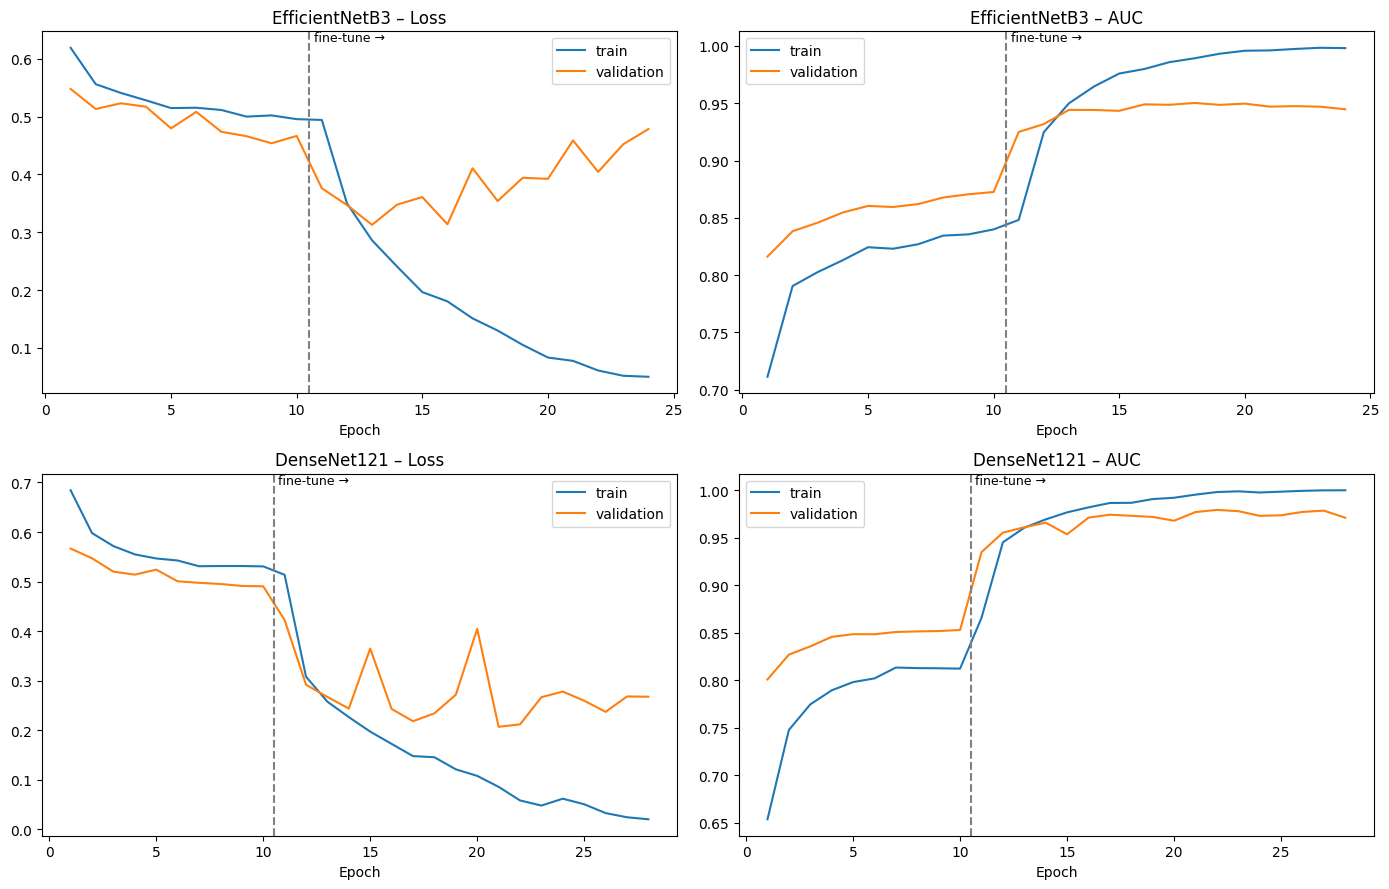

In [16]:
# Training curves (warm-up + fine-tune), useful as a supplementary figure
fig, axes = plt.subplots(len(DL_HISTORY), 2, figsize=(14, 4.5 * len(DL_HISTORY)), squeeze=False)
for r, (name, h) in enumerate(DL_HISTORY.items()):
    w = h["warmup_epochs_run"]
    for c, (key, label) in enumerate([("loss", "Loss"), ("auc", "AUC")]):
        tr = h["warmup"][key] + h["finetune"][key]
        va = h["warmup"]["val_" + key] + h["finetune"]["val_" + key]
        ep = np.arange(1, len(tr) + 1)
        ax = axes[r, c]
        ax.plot(ep, tr, label="train"); ax.plot(ep, va, label="validation")
        ax.axvline(w + 0.5, ls="--", c="gray"); ax.text(w + 0.7, ax.get_ylim()[1], "fine-tune →", va="top", fontsize=9)
        ax.set_title(f"{name} – {label}"); ax.set_xlabel("Epoch"); ax.legend()
plt.tight_layout(); plt.savefig(os.path.join(OUTPUT_DIR, "dl_training_curves.png"), dpi=300); plt.show()

model_A.save(os.path.join(OUTPUT_DIR, "EfficientNetB3_final.keras"))
model_B.save(os.path.join(OUTPUT_DIR, "DenseNet121_final.keras"))

## Handcrafted features (HOG + LBP + colour histogram) for SVM / XGBoost

In [17]:
LBP_P, LBP_R = 8, 1
LBP_BINS = LBP_P + 2            # 'uniform' LBP has exactly P+2 possible codes -> fixed length

def load_img_basic(path, resize=RESIZE_ML):
    img = io.imread(path)
    if img.ndim == 2:
        img = np.stack([img] * 3, axis=-1)
    elif img.shape[2] == 4:
        img = img[..., :3]
    img = transform.resize(img, (resize, resize), anti_aliasing=True, preserve_range=True)
    return np.clip(img, 0, 255).astype(np.uint8)

def feat_hog(img_rgb):
    return hog(rgb2gray(img_rgb), pixels_per_cell=(32, 32), cells_per_block=(2, 2),
               orientations=6, block_norm='L2-Hys')

def feat_lbp(img_rgb):
    small = transform.resize(rgb2gray(img_rgb), (64, 64), anti_aliasing=True)
    lbp = local_binary_pattern((small * 255).astype(np.uint8), LBP_P, LBP_R, method='uniform')
    hist, _ = np.histogram(lbp.ravel(), bins=LBP_BINS, range=(0, LBP_BINS), density=True)
    return hist

def feat_colorhist(img_rgb, bins=32):
    return np.concatenate([np.histogram(img_rgb[..., i], bins=bins, range=(0, 256), density=True)[0]
                           for i in range(3)])

def extract_one(path):
    img = load_img_basic(path)
    return np.concatenate([feat_hog(img), feat_lbp(img), feat_colorhist(img)]).astype(np.float32)

def extract_features(paths, n_jobs=-1):
    return np.array(Parallel(n_jobs=n_jobs, backend="loky")(delayed(extract_one)(p) for p in paths),
                    dtype=np.float32)

X_train = extract_features(train_df['filepath'].values)
X_val   = extract_features(val_df['filepath'].values)
X_test  = extract_features(test_df['filepath'].values)
n_hog = len(feat_hog(load_img_basic(train_df['filepath'].iloc[0])))
print(f"Features: train {X_train.shape}, val {X_val.shape}, test {X_test.shape} "
      f"(HOG={n_hog}, LBP={LBP_BINS}, colour={3*32})")

Features: train (4800, 322), val (600, 322), test (600, 322) (HOG=216, LBP=10, colour=96)


In [18]:
# ---------------- SVM (RBF) : 5-fold CV grid search on the TRAINING split only ----------------
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
svm_search = GridSearchCV(
    Pipeline([("scaler", StandardScaler()), ("svc", SVC(kernel="rbf"))]),
    param_grid={"svc__C": [0.1, 0.5, 1, 3, 10, 20], "svc__gamma": ["scale", 0.1, 0.01, 0.001]},
    cv=cv5, scoring="accuracy", n_jobs=-1, verbose=1)
svm_search.fit(X_train, y_train)
SVM_BEST_PARAMS = {k.split("__")[1]: v for k, v in svm_search.best_params_.items()}
print("Best SVM params:", SVM_BEST_PARAMS, "| CV acc:", round(svm_search.best_score_, 4))

# Final SVM: best params, probability outputs (Platt scaling), trained on the training split
svm_best = Pipeline([("scaler", StandardScaler()),
                     ("svc", SVC(kernel="rbf", probability=True, random_state=SEED, **SVM_BEST_PARAMS))])
svm_best.fit(X_train, y_train)
print("SVM validation acc:", round(accuracy_score(y_val, svm_best.predict(X_val)), 4))
svm_prob = svm_best.predict_proba(X_test)[:, 1]
_ = evaluate_model("SVM", y_test, svm_prob)

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best SVM params: {'C': 10, 'gamma': 0.001} | CV acc: 0.74
SVM validation acc: 0.7683

=== SVM (test set, n=600) ===
acc=0.7183  prec=0.7191  rec=0.7167  spec=0.7200  f1=0.7179  auc=0.8082
Confusion (TN, FP, FN, TP): 216, 84, 85, 215
95% CI  acc: [0.6833, 0.7534]   auc: [0.7731, 0.8420]
              precision    recall  f1-score   support

      normal     0.7176    0.7200    0.7188       300
    glaucoma     0.7191    0.7167    0.7179       300

    accuracy                         0.7183       600
   macro avg     0.7183    0.7183    0.7183       600
weighted avg     0.7183    0.7183    0.7183       600



In [19]:
# ---------------- XGBoost : 5-fold CV randomized search on the TRAINING split only ----------------
xgb_search = RandomizedSearchCV(
    xgb.XGBClassifier(objective="binary:logistic", eval_metric="logloss", tree_method="hist",
                      random_state=SEED, n_jobs=1),
    param_distributions={
        "n_estimators": [200, 400, 600, 800],
        "max_depth": [3, 4, 6, 8],
        "learning_rate": [0.01, 0.05, 0.1],
        "subsample": [0.7, 0.8, 1.0],
        "colsample_bytree": [0.7, 0.8, 1.0],
        "min_child_weight": [1, 3, 5],
    },
    n_iter=20, cv=cv5, scoring="accuracy", n_jobs=-1, random_state=SEED, verbose=1, refit=True)
xgb_search.fit(X_train, y_train)
XGB_BEST_PARAMS = xgb_search.best_params_
print("Best XGB params:", XGB_BEST_PARAMS, "| CV acc:", round(xgb_search.best_score_, 4))

xgb_best = xgb_search.best_estimator_          # refit on the full training split with best params
print("XGB validation acc:", round(accuracy_score(y_val, xgb_best.predict(X_val)), 4))
xgb_prob = xgb_best.predict_proba(X_test)[:, 1]
_ = evaluate_model("XGBoost", y_test, xgb_prob)

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best XGB params: {'subsample': 0.8, 'n_estimators': 800, 'min_child_weight': 3, 'max_depth': 4, 'learning_rate': 0.1, 'colsample_bytree': 0.7} | CV acc: 0.756
XGB validation acc: 0.775

=== XGBoost (test set, n=600) ===
acc=0.7400  prec=0.7368  rec=0.7467  spec=0.7333  f1=0.7417  auc=0.8230
Confusion (TN, FP, FN, TP): 220, 80, 76, 224
95% CI  acc: [0.7067, 0.7733]   auc: [0.7912, 0.8535]
              precision    recall  f1-score   support

      normal     0.7432    0.7333    0.7383       300
    glaucoma     0.7368    0.7467    0.7417       300

    accuracy                         0.7400       600
   macro avg     0.7400    0.7400    0.7400       600
weighted avg     0.7400    0.7400    0.7400       600



## Combined results: table, bar charts, ROC curves, confusion matrices

         Model Type  Accuracy  Precision  Recall  Specificity     F1    AUC         Acc_CI95         AUC_CI95  TN  FP  FN  TP
           SVM   ML    0.7183     0.7191  0.7167       0.7200 0.7179 0.8082 [0.6833, 0.7534] [0.7731, 0.8420] 216  84  85 215
       XGBoost   ML    0.7400     0.7368  0.7467       0.7333 0.7417 0.8230 [0.7067, 0.7733] [0.7912, 0.8535] 220  80  76 224
EfficientNetB3   DL    0.8583     0.8881  0.8200       0.8967 0.8527 0.9418 [0.8283, 0.8867] [0.9216, 0.9600] 269  31  54 246
   DenseNet121   DL    0.9083     0.8990  0.9200       0.8967 0.9094 0.9674 [0.8833, 0.9317] [0.9538, 0.9796] 269  31  24 276


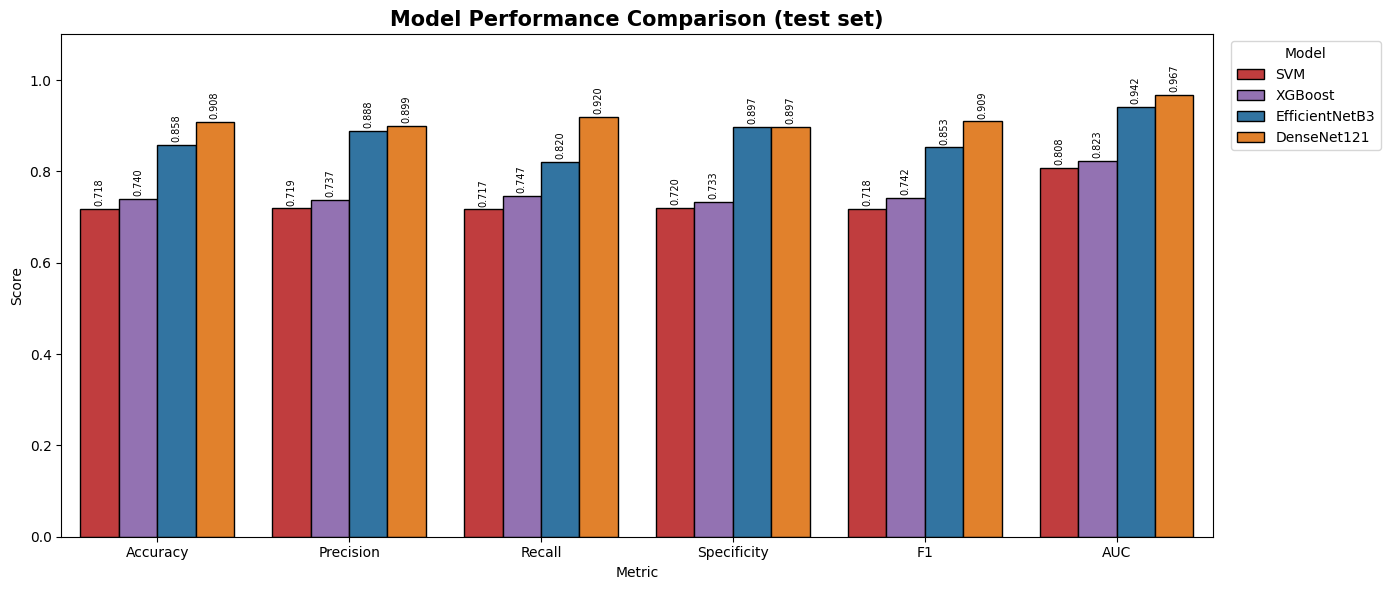

In [20]:
MODEL_ORDER  = ["SVM", "XGBoost", "EfficientNetB3", "DenseNet121"]
MODEL_COLORS = {"SVM": "#d62728", "XGBoost": "#9467bd", "EfficientNetB3": "#1f77b4", "DenseNet121": "#ff7f0e"}

rows = []
for name in MODEL_ORDER:
    m = RESULTS[name]["metrics"]
    rows.append({"Model": name, "Type": "DL" if name in DL_HISTORY else "ML",
                 "Accuracy": m["accuracy"], "Precision": m["precision"], "Recall": m["recall"],
                 "Specificity": m["specificity"], "F1": m["f1"], "AUC": m["auc"],
                 "Acc_CI95": "[{:.4f}, {:.4f}]".format(*m["ci95"]["accuracy"]),
                 "AUC_CI95": "[{:.4f}, {:.4f}]".format(*m["ci95"]["auc"]),
                 "TN": m["tn"], "FP": m["fp"], "FN": m["fn"], "TP": m["tp"]})
results_df = pd.DataFrame(rows)
results_df.to_csv(os.path.join(OUTPUT_DIR, "combined_results.csv"), index=False)
print(results_df.round(4).to_string(index=False))

# Bar chart of all metrics
metric_cols = ["Accuracy", "Precision", "Recall", "Specificity", "F1", "AUC"]
melt = results_df.melt(id_vars="Model", value_vars=metric_cols, var_name="Metric", value_name="Score")
plt.figure(figsize=(14, 6))
ax = sns.barplot(data=melt, x="Metric", y="Score", hue="Model", hue_order=MODEL_ORDER,
                 palette=MODEL_COLORS, edgecolor="black")
for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom", fontsize=7, rotation=90, xytext=(0, 2), textcoords="offset points")
plt.ylim(0, 1.1); plt.title("Model Performance Comparison (test set)", fontsize=15, weight="bold")
plt.legend(title="Model", bbox_to_anchor=(1.01, 1), loc="upper left"); plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "all_models_metrics.png"), dpi=300, bbox_inches="tight"); plt.show()

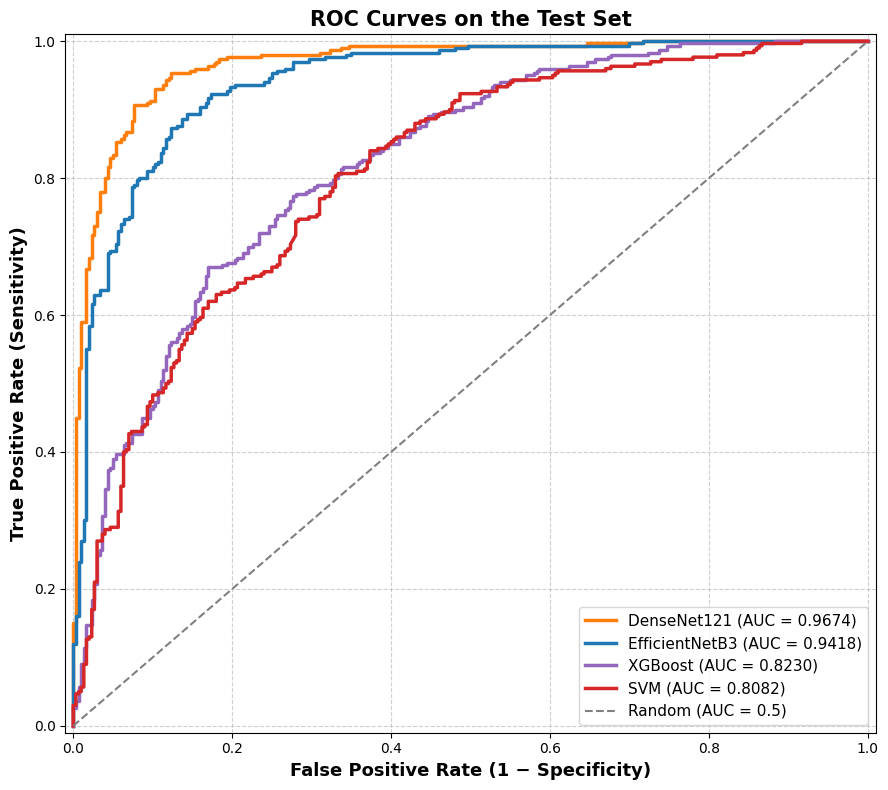

In [21]:
# REAL ROC curves computed from each model's predicted probabilities on the test set
plt.figure(figsize=(9, 8))
for name in MODEL_ORDER[::-1]:
    fpr, tpr, _ = roc_curve(y_test, RESULTS[name]["y_prob"])
    plt.plot(fpr, tpr, lw=2.5, color=MODEL_COLORS[name],
             label=f"{name} (AUC = {RESULTS[name]['metrics']['auc']:.4f})")
plt.plot([0, 1], [0, 1], "--", color="gray", lw=1.5, label="Random (AUC = 0.5)")
plt.xlabel("False Positive Rate (1 − Specificity)", fontsize=13, weight="bold")
plt.ylabel("True Positive Rate (Sensitivity)", fontsize=13, weight="bold")
plt.title("ROC Curves on the Test Set", fontsize=15, weight="bold")
plt.legend(loc="lower right", fontsize=11); plt.grid(ls="--", alpha=0.6)
plt.xlim(-0.01, 1.01); plt.ylim(-0.01, 1.01); plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "roc_all_models.png"), dpi=300, bbox_inches="tight"); plt.show()

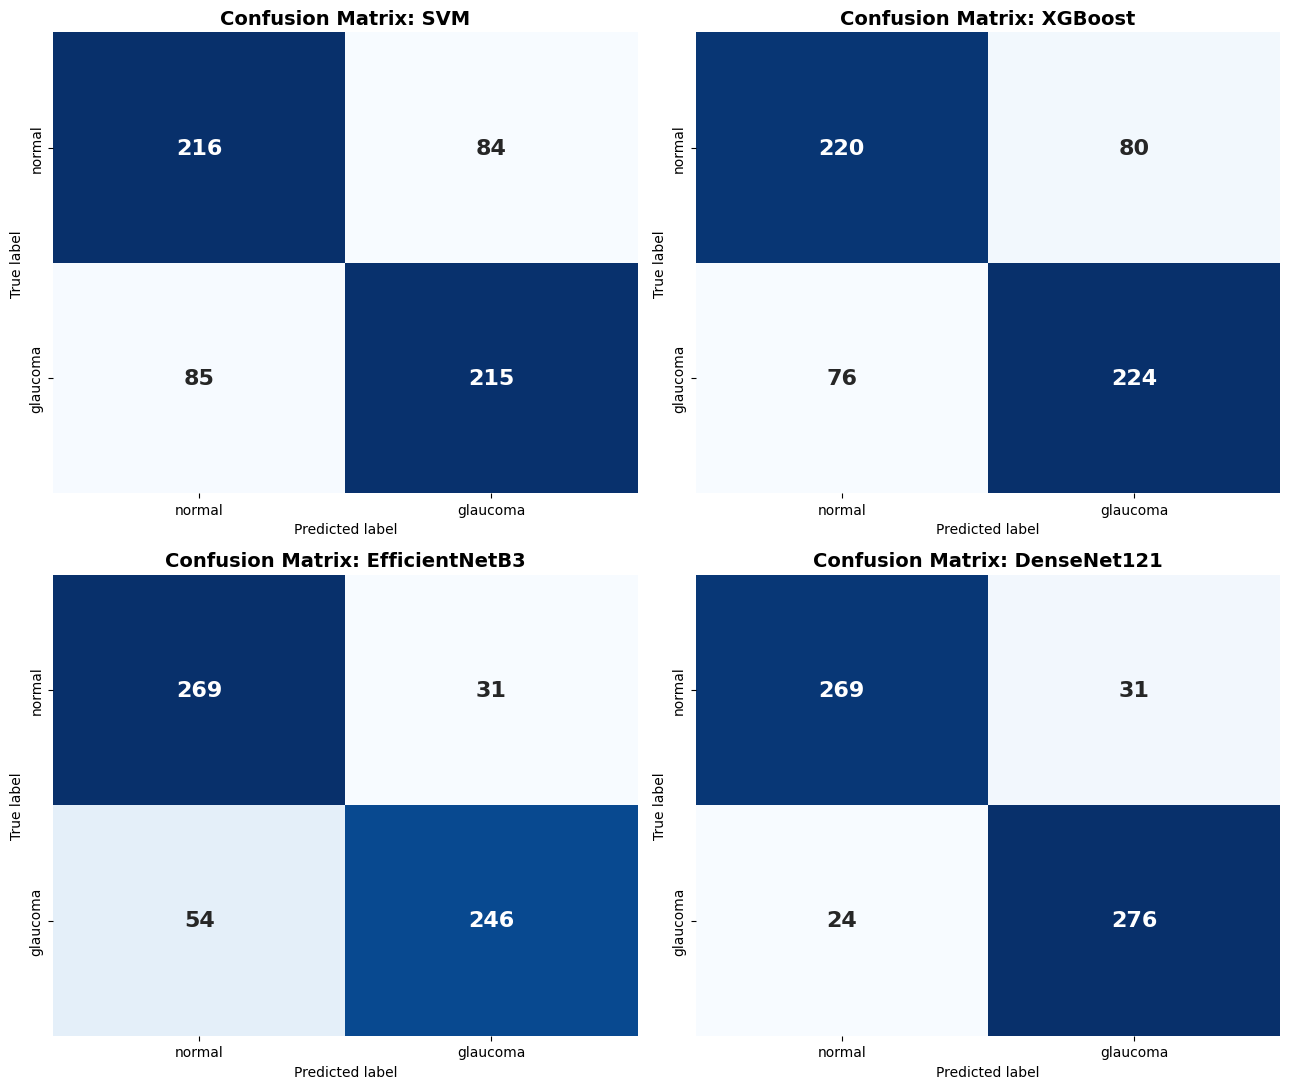

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(13, 11)); axes = axes.ravel()
for ax, name in zip(axes, MODEL_ORDER):
    cm = confusion_matrix(y_test, RESULTS[name]["y_pred"], labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=CLASSES, yticklabels=CLASSES, annot_kws={"size": 16, "weight": "bold"})
    ax.set_title(f"Confusion Matrix: {name}", fontsize=14, weight="bold")
    ax.set_xlabel("Predicted label"); ax.set_ylabel("True label")
plt.tight_layout(); plt.savefig(os.path.join(OUTPUT_DIR, "all_models_confusion_matrices.png"), dpi=300); plt.show()

In [23]:
# Statistical significance: exact McNemar test on paired test-set predictions
def mcnemar_exact(y, pred_a, pred_b):
    a_ok, b_ok = pred_a == y, pred_b == y
    n01 = int(np.sum(a_ok & ~b_ok)); n10 = int(np.sum(~a_ok & b_ok))
    p = binomtest(n01, n01 + n10, 0.5).pvalue if (n01 + n10) > 0 else 1.0
    return n01, n10, p

MCNEMAR = []
for a, b in [("DenseNet121", "EfficientNetB3"), ("DenseNet121", "XGBoost"), ("DenseNet121", "SVM"),
             ("EfficientNetB3", "XGBoost"), ("EfficientNetB3", "SVM"), ("XGBoost", "SVM")]:
    n01, n10, p = mcnemar_exact(y_test, RESULTS[a]["y_pred"], RESULTS[b]["y_pred"])
    MCNEMAR.append({"Model A": a, "Model B": b, "A right / B wrong": n01, "A wrong / B right": n10, "p_value": p})
mcnemar_df = pd.DataFrame(MCNEMAR)
mcnemar_df.to_csv(os.path.join(OUTPUT_DIR, "mcnemar_tests.csv"), index=False)
print(mcnemar_df.to_string(index=False))

       Model A        Model B  A right / B wrong  A wrong / B right      p_value
   DenseNet121 EfficientNetB3                 53                 23 7.645817e-04
   DenseNet121        XGBoost                123                 22 3.205794e-18
   DenseNet121            SVM                140                 26 4.337979e-20
EfficientNetB3        XGBoost                111                 40 6.473733e-09
EfficientNetB3            SVM                127                 43 7.964577e-11
       XGBoost            SVM                 50                 37 1.979791e-01


## Inference time (per image, end-to-end: image file → prediction)

Device: GPU, batch size 1, n=100 images
         Model  Mean (ms/image)  Std (ms)  Classifier only (ms)
           SVM           14.896     2.806                 1.514
       XGBoost           13.426     0.588                 0.461
EfficientNetB3           16.998     0.974                   NaN
   DenseNet121           18.903     0.816                   NaN


/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1458: RuntimeWarning: invalid value encountered in greater
  has_large_values = (abs_vals > 1e6).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in less
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()
/usr/local/lib/python3.11/dist-packages/pandas/io/formats/format.py:1459: RuntimeWarning: invalid value encountered in greater
  has_small_values = ((abs_vals < 10 ** (-self.digits)) & (abs_vals > 0)).any()


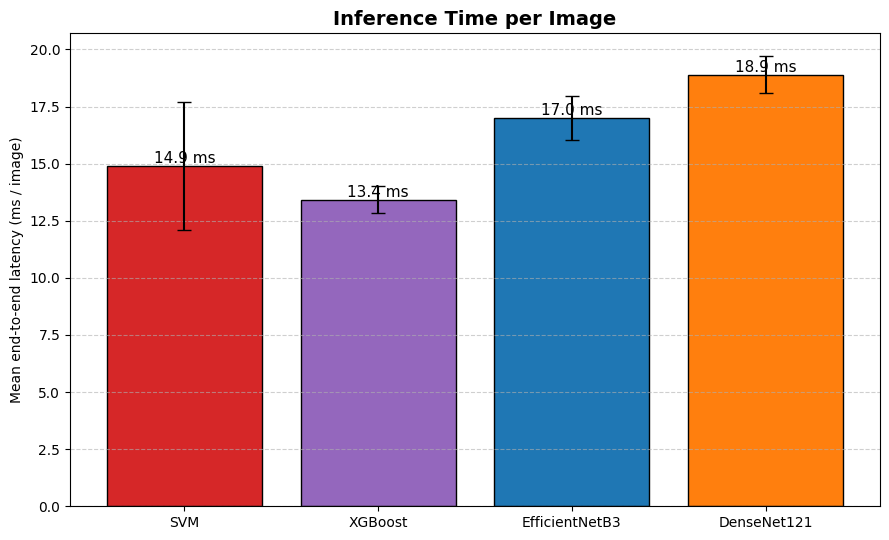

In [24]:
timing_paths = test_df.sample(n=min(N_TIMING, len(test_df)), random_state=SEED)['filepath'].values

def time_dl(model, paths):
    infer = tf.function(lambda x: model(x, training=False))
    infer(tf.expand_dims(decode_img(paths[0]), 0))                       # warm-up / graph tracing
    t = []
    for p in paths:
        t0 = time.perf_counter()
        _ = infer(tf.expand_dims(decode_img(p), 0)).numpy()
        t.append(time.perf_counter() - t0)
    return np.array(t)

def time_ml(clf, paths):
    clf.predict_proba(extract_one(paths[0])[None])                       # warm-up
    t_total, t_clf = [], []
    for p in paths:
        t0 = time.perf_counter(); f = extract_one(p)[None]
        t1 = time.perf_counter(); clf.predict_proba(f)
        t2 = time.perf_counter()
        t_total.append(t2 - t0); t_clf.append(t2 - t1)
    return np.array(t_total), np.array(t_clf)

timing_rows = []
for name, mdl in [("EfficientNetB3", model_A), ("DenseNet121", model_B)]:
    t = time_dl(mdl, timing_paths)
    timing_rows.append({"Model": name, "Mean (ms/image)": t.mean() * 1e3, "Std (ms)": t.std() * 1e3,
                        "Classifier only (ms)": np.nan})
for name, clf in [("SVM", svm_best), ("XGBoost", xgb_best)]:
    tt, tc = time_ml(clf, timing_paths)
    timing_rows.append({"Model": name, "Mean (ms/image)": tt.mean() * 1e3, "Std (ms)": tt.std() * 1e3,
                        "Classifier only (ms)": tc.mean() * 1e3})
inference_times_df = pd.DataFrame(timing_rows).set_index("Model").loc[MODEL_ORDER].reset_index()
inference_times_df.to_csv(os.path.join(OUTPUT_DIR, "inference_times.csv"), index=False)
print(f"Device: {'GPU' if tf.config.list_physical_devices('GPU') else 'CPU'}, batch size 1, n={len(timing_paths)} images")
print(inference_times_df.round(3).to_string(index=False))

plt.figure(figsize=(9, 5.5))
bars = plt.bar(inference_times_df["Model"], inference_times_df["Mean (ms/image)"],
               yerr=inference_times_df["Std (ms)"], capsize=5,
               color=[MODEL_COLORS[m] for m in inference_times_df["Model"]], edgecolor="black")
for b, v in zip(bars, inference_times_df["Mean (ms/image)"]):
    plt.text(b.get_x() + b.get_width() / 2, v, f"{v:.1f} ms", ha="center", va="bottom", fontsize=11)
plt.ylabel("Mean end-to-end latency (ms / image)"); plt.title("Inference Time per Image", fontsize=14, weight="bold")
plt.grid(axis="y", ls="--", alpha=0.6); plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "inference_time_comparison.png"), dpi=300); plt.show()

## Grad-CAM (float32-safe) + quantitative background-attention audit

In [25]:
def get_img_array(img_path, img_size=IMG_SIZE):
    return tf.expand_dims(decode_img(img_path, img_size), 0)          # [0,255], same as training input

def find_last_spatial_layer(base_model):
    for layer in reversed(base_model.layers):
        try:
            out = layer.output
        except Exception:
            continue
        if isinstance(out, (list, tuple)):
            if not out: continue
            out = out[0]
        if getattr(out, "shape", None) is not None and len(out.shape) == 4:
            return layer.name
    raise ValueError("No 4-D layer found for Grad-CAM")

def build_gradcam_components(model, last_conv_layer_name=None):
    base, base_idx = get_base_submodel(model)
    if last_conv_layer_name is None:
        last_conv_layer_name = find_last_spatial_layer(base)
    conv_layer = base.get_layer(last_conv_layer_name)
    grad_model = keras.Model(base.inputs, [conv_layer.output, base.output])
    pre_layers  = [l for l in model.layers[:base_idx] if not isinstance(l, layers.InputLayer)]   # e.g. DenseNet normalisation
    head_layers = [l for l in model.layers[base_idx + 1:] if l.name != "sigmoid_out"]          # up to the logit
    return {"grad_model": grad_model, "pre": pre_layers, "head": head_layers, "conv_name": last_conv_layer_name}

def gradcam(comp, img_array):
    # Returns (heatmap HxW in [0,1] float32, pred_index, pred_prob, valid_flag).
    with tf.GradientTape() as tape:
        x = img_array
        for l in comp["pre"]:
            x = l(x)
        conv_out, feats = comp["grad_model"](x, training=False)
        h = feats
        for l in comp["head"]:
            h = l(h, training=False)
        logit = tf.cast(h[:, 0], tf.float32)
        prob = float(tf.sigmoid(logit)[0])
        pred_index = int(prob >= 0.5)
        score = logit if pred_index == 1 else -logit                  # class-specific target (pre-sigmoid)
    grads = tape.gradient(score, conv_out)
    conv_out = tf.cast(conv_out, tf.float32)[0]                       # float32 -> no fp16 underflow / 0/0
    grads = tf.cast(grads, tf.float32)
    weights = tf.reduce_mean(grads, axis=(0, 1, 2))
    heatmap = tf.nn.relu(tf.reduce_sum(conv_out * weights, axis=-1)).numpy()
    mx = float(np.nanmax(heatmap)) if np.isfinite(heatmap).any() else 0.0
    valid = bool(np.isfinite(heatmap).all() and mx > 0)
    heatmap = heatmap / mx if valid else np.zeros_like(heatmap, dtype=np.float32)
    pred_prob = prob if pred_index == 1 else 1.0 - prob
    return heatmap.astype(np.float32), pred_index, pred_prob, valid

def load_rgb_resized(img_path, img_size=IMG_SIZE):
    orig = io.imread(img_path)
    if orig.ndim == 2: orig = np.stack([orig] * 3, axis=-1)
    elif orig.shape[-1] == 4: orig = orig[..., :3]
    return np.clip(transform.resize(orig, (img_size, img_size), preserve_range=True), 0, 255).astype(np.uint8)

def overlay_gradcam(img_path, heatmap, img_size=IMG_SIZE, alpha=0.45):
    orig = load_rgb_resized(img_path, img_size)
    hm = np.clip(transform.resize(heatmap, (img_size, img_size), order=1, preserve_range=True), 0, 1)
    colored = (plt.cm.jet(hm)[..., :3] * 255).astype(np.uint8)
    return orig, (orig * (1 - alpha) + colored * alpha).astype(np.uint8)

GRADCAM = {name: build_gradcam_components(m) for name, m in [("EfficientNetB3", model_A), ("DenseNet121", model_B)]}
for k, v in GRADCAM.items():
    print(f"{k}: Grad-CAM layer = {v['conv_name']}, pre-processing layers = {[l.name for l in v['pre']]}")

EfficientNetB3: Grad-CAM layer = top_activation, pre-processing layers = []
DenseNet121: Grad-CAM layer = relu, pre-processing layers = ['densenet_rescale', 'densenet_normalize']


/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_5']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)
/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_397']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)
/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_5']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)
/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_397']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.wa

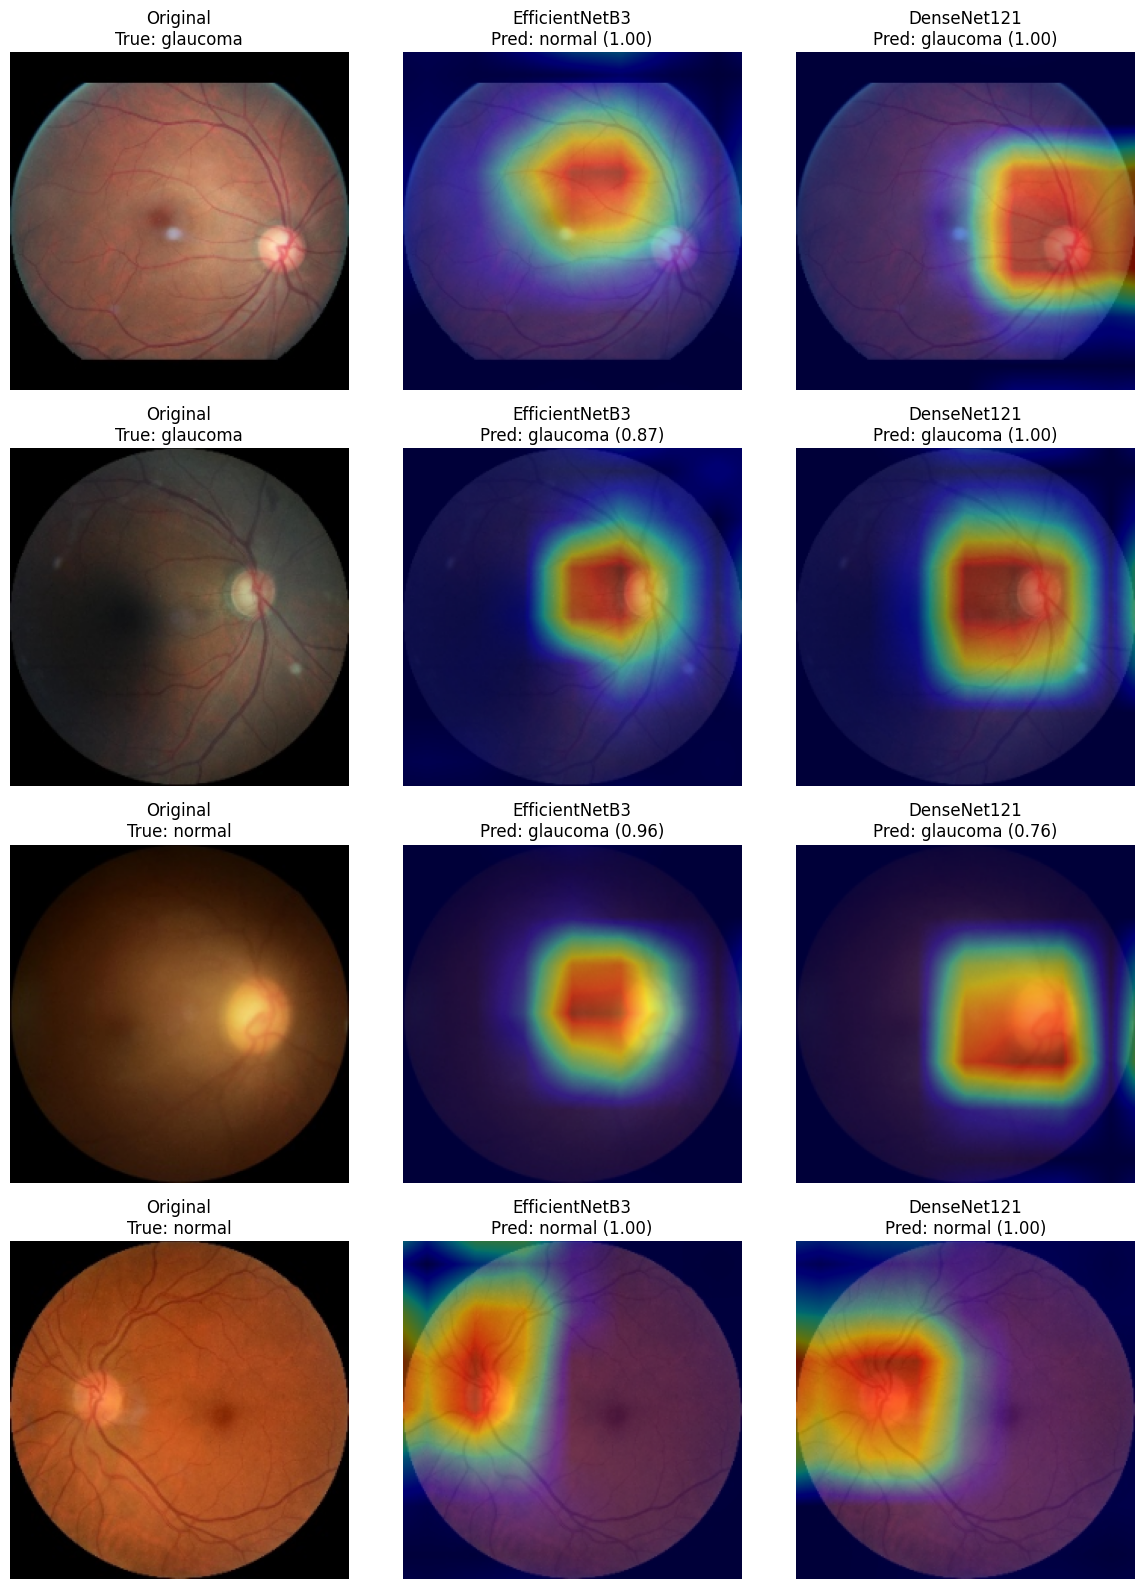

In [26]:
def grad_cam_grid(df_samples, n=4, seed=SEED):
    samples = pd.concat([df_samples[df_samples.label == 1].sample(n // 2, random_state=seed),
                         df_samples[df_samples.label == 0].sample(n - n // 2, random_state=seed)])
    fig, axes = plt.subplots(n, len(GRADCAM) + 1, figsize=(4 * (len(GRADCAM) + 1), 4 * n), squeeze=False)
    for r, (_, s) in enumerate(samples.iterrows()):
        axes[r, 0].imshow(load_rgb_resized(s.filepath)); axes[r, 0].set_title(f"Original\nTrue: {s.class_name}")
        axes[r, 0].axis("off")
        for c, (mname, comp) in enumerate(GRADCAM.items(), start=1):
            hm, pi, pp, _ = gradcam(comp, get_img_array(s.filepath))
            _, ov = overlay_gradcam(s.filepath, hm)
            axes[r, c].imshow(ov); axes[r, c].set_title(f"{mname}\nPred: {CLASSES[pi]} ({pp:.2f})"); axes[r, c].axis("off")
    plt.tight_layout(); plt.savefig(os.path.join(OUTPUT_DIR, "gradcam_grid.png"), dpi=200); plt.show()

grad_cam_grid(test_df, n=4)

In [27]:
def build_fov_mask(img_path, img_size=IMG_SIZE, brightness_thresh=12):
    # True = retina (field of view), False = black background border
    return load_rgb_resized(img_path, img_size).mean(axis=-1) > brightness_thresh

def background_attention_fraction(heatmap, fov_mask, top_quantile=0.90):
    hm = transform.resize(heatmap, fov_mask.shape, order=1, mode="edge", anti_aliasing=False, preserve_range=True)
    hot = hm >= np.quantile(hm, top_quantile)
    return float((hot & ~fov_mask).sum()) / float(hot.sum()) if hot.sum() else np.nan

def run_gradcam_audit(model_name, df_, top_quantile=0.90, bg_flag_thresh=0.15):
    comp = GRADCAM[model_name]; rows = []
    for i, (_, r) in enumerate(df_.iterrows()):
        hm, pi, pp, valid = gradcam(comp, get_img_array(r.filepath))
        bg = background_attention_fraction(hm, build_fov_mask(r.filepath), top_quantile) if valid else np.nan
        rows.append({"model": model_name, "filepath": r.filepath, "true_label": r.class_name,
                     "pred_label": CLASSES[pi], "pred_prob": pp, "correct": CLASSES[pi] == r.class_name,
                     "valid_heatmap": valid, "bg_attention_fraction": bg,
                     "background_attention_flag": bool(valid and bg > bg_flag_thresh)})
        if (i + 1) % 100 == 0:
            print(f"  [{model_name}] {i + 1}/{len(df_)}")
    return pd.DataFrame(rows)

audit_full = pd.concat([run_gradcam_audit(m, test_df) for m in GRADCAM], ignore_index=True)
audit_full.to_csv(os.path.join(OUTPUT_DIR, "gradcam_audit_full.csv"), index=False)

agg = dict(n=("filepath", "count"), accuracy=("correct", "mean"), mean_pred_confidence=("pred_prob", "mean"),
           n_invalid_heatmaps=("valid_heatmap", lambda s: int((~s).sum())),
           mean_bg_attention_fraction=("bg_attention_fraction", "mean"),       # NaN (invalid) excluded
           pct_background_attention_flagged=("background_attention_flag", "mean"))
summary_by_class = audit_full.groupby(["model", "true_label"]).agg(**agg).reset_index()
overall_summary  = audit_full.groupby("model").agg(**agg).reset_index()
for d in (summary_by_class, overall_summary):
    d["pct_background_attention_flagged"] *= 100
summary_by_class.to_csv(os.path.join(OUTPUT_DIR, "gradcam_audit_summary_by_class.csv"), index=False)
overall_summary.to_csv(os.path.join(OUTPUT_DIR, "gradcam_audit_summary_overall.csv"), index=False)
print("=== By model x class ===\n", summary_by_class.round(4).to_string(index=False))
print("\n=== Overall ===\n", overall_summary.round(4).to_string(index=False))

crosstab = (audit_full.groupby(["model", "background_attention_flag"])["correct"]
            .agg(["count", "mean"]).rename(columns={"mean": "accuracy"}).reset_index())
print("\n=== Accuracy vs background-attention flag ===\n", crosstab.round(4).to_string(index=False))

/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_5']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)
/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_5']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)
/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_5']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)
/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_5']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(m

  [EfficientNetB3] 100/600


/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_5']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)
/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_5']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)
/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_5']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)
/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_5']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(m

  [EfficientNetB3] 200/600


/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_5']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)
/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_5']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)
/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_5']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)
/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_5']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(m

  [EfficientNetB3] 300/600


... (14 outputs left out)

/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_397']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)
/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_397']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)
/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_397']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)
/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_397']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warning

  [DenseNet121] 500/600


/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_397']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)
/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_397']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)
/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_397']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)
/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_397']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warning

  [DenseNet121] 600/600
=== By model x class ===
          model true_label   n  accuracy  mean_pred_confidence  n_invalid_heatmaps  mean_bg_attention_fraction  pct_background_attention_flagged
   DenseNet121   glaucoma 300    0.9200                0.9484                   0                      0.0165                            2.3333
   DenseNet121     normal 300    0.8967                0.9560                   0                      0.0229                            3.6667
EfficientNetB3   glaucoma 300    0.8200                0.9130                   0                      0.0198                            4.3333
EfficientNetB3     normal 300    0.8967                0.9436                   0                      0.0215                            2.6667

=== Overall ===
          model   n  accuracy  mean_pred_confidence  n_invalid_heatmaps  mean_bg_attention_fraction  pct_background_attention_flagged
   DenseNet121 600    0.9083                0.9522                   0         

/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_5']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)
/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_5']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)
/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_5']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)
/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_5']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(m

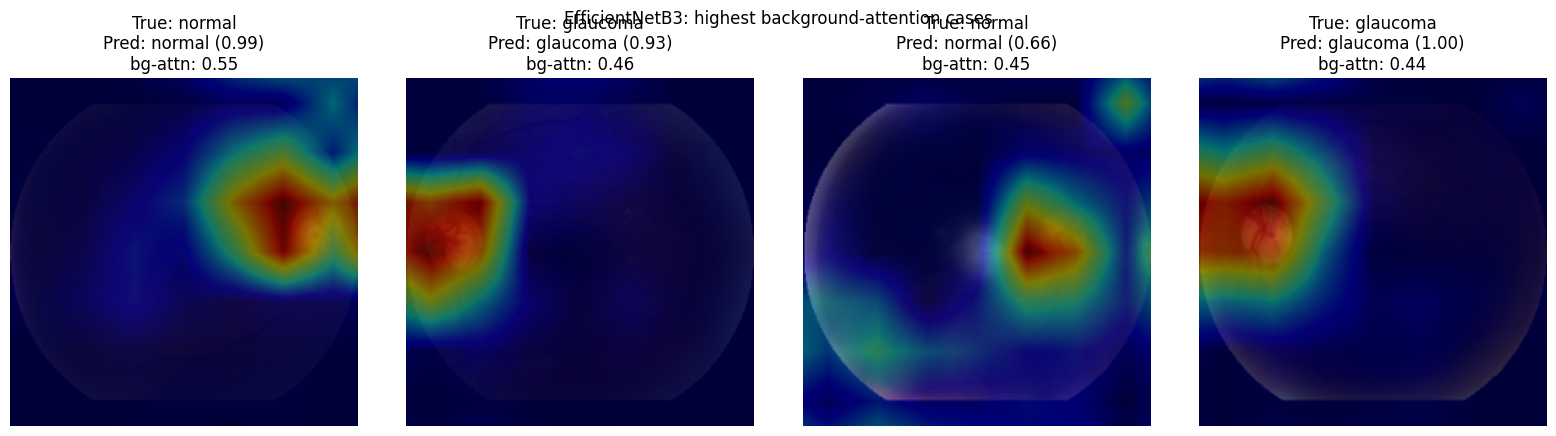

/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_397']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)
/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_397']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)
/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_397']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)
/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor_397']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warning

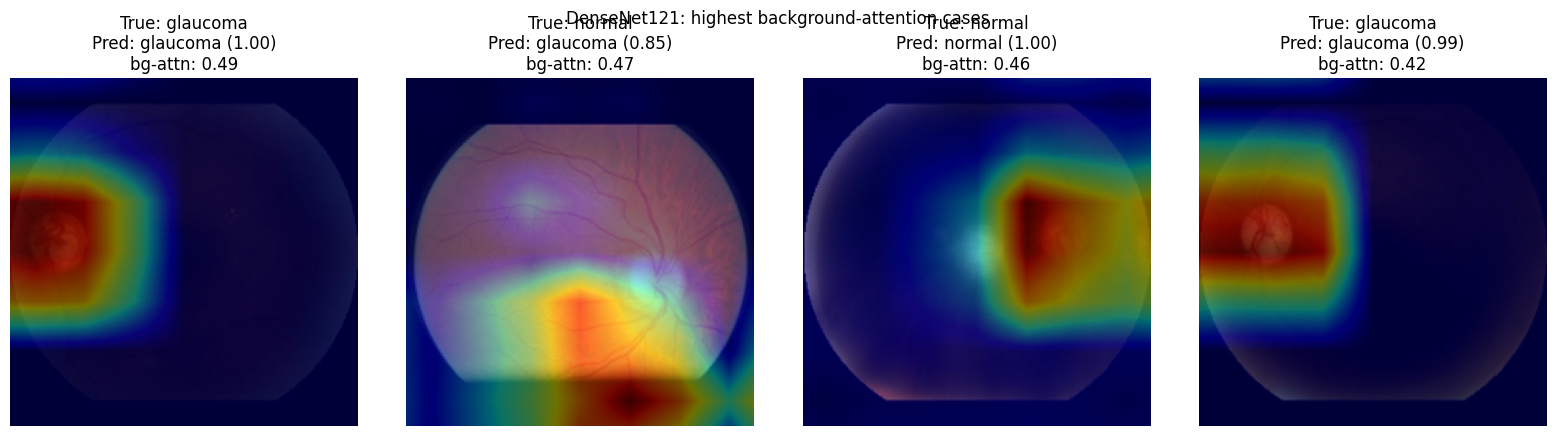

In [28]:
def show_worst_offenders(model_name, n=4):
    worst = (audit_full[(audit_full.model == model_name) & audit_full.valid_heatmap]
             .sort_values("bg_attention_fraction", ascending=False).head(n))
    fig, axes = plt.subplots(1, n, figsize=(4 * n, 4.4), squeeze=False)
    for ax, (_, r) in zip(axes[0], worst.iterrows()):
        hm, _, _, _ = gradcam(GRADCAM[model_name], get_img_array(r.filepath))
        _, ov = overlay_gradcam(r.filepath, hm)
        ax.imshow(ov); ax.axis("off")
        ax.set_title(f"True: {r.true_label}\nPred: {r.pred_label} ({r.pred_prob:.2f})\nbg-attn: {r.bg_attention_fraction:.2f}")
    plt.suptitle(f"{model_name}: highest background-attention cases"); plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, f"{model_name}_worst_bg_attention.png"), dpi=200); plt.show()

for m in GRADCAM:
    show_worst_offenders(m)

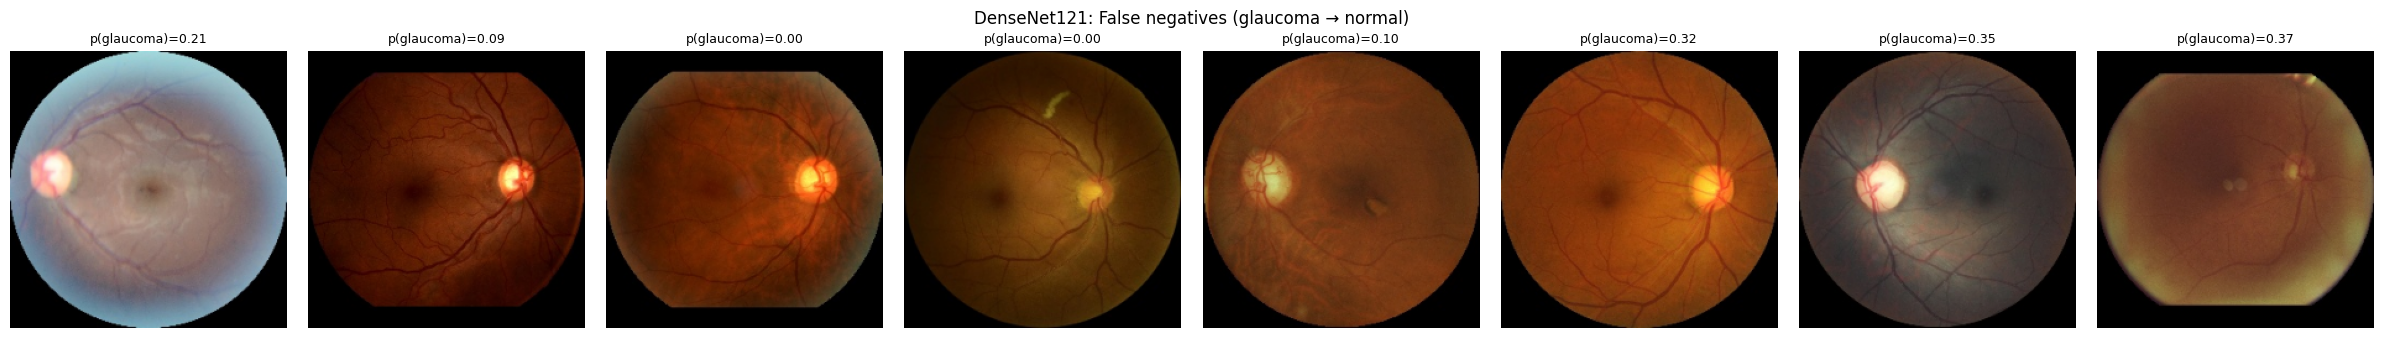

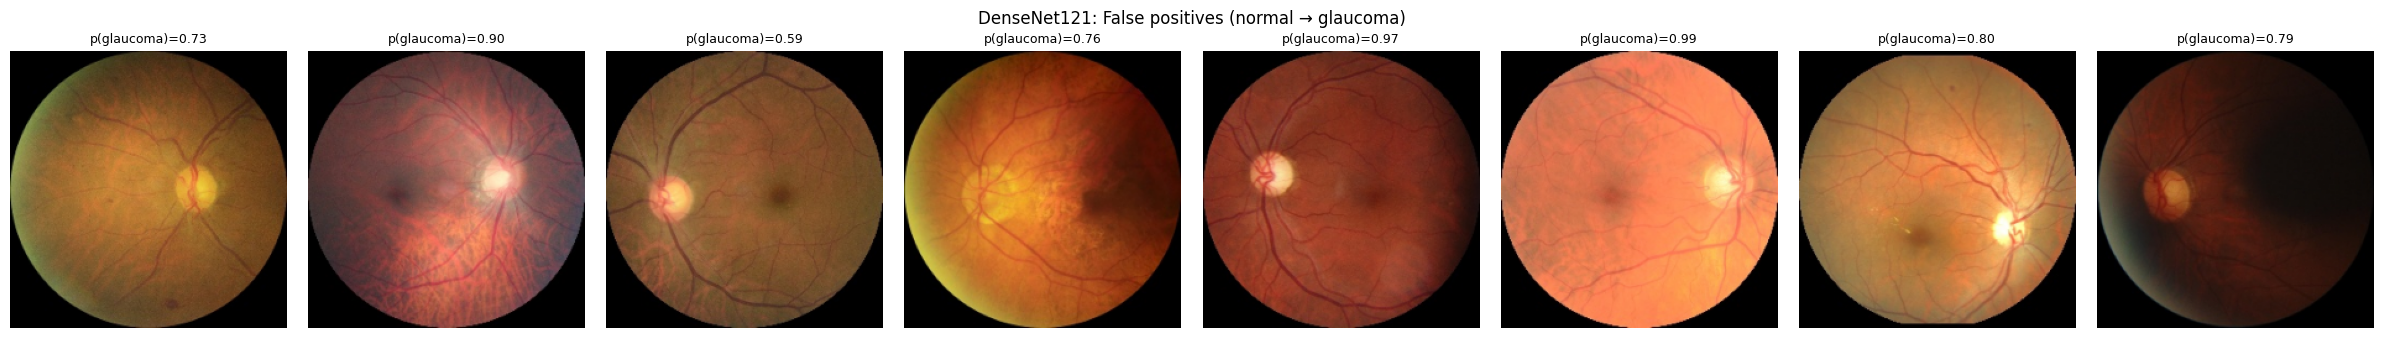

DenseNet121: 55 misclassified test images saved to CSV.


In [29]:
# Misclassified test images of the best model -> use these for the manual misclassification analysis (Sec. 4.5)
best_dl = max(DL_HISTORY, key=lambda k: RESULTS[k]["metrics"]["auc"])
res = RESULTS[best_dl]
mis = test_df.assign(y_prob=res["y_prob"], y_pred=res["y_pred"])
mis = mis[mis.y_pred != mis.label]
mis.assign(error=np.where(mis.label == 1, "false_negative", "false_positive")) \
   .to_csv(os.path.join(OUTPUT_DIR, f"{best_dl}_misclassified.csv"), index=False)

for err, sub in [("False negatives (glaucoma → normal)", mis[mis.label == 1]),
                 ("False positives (normal → glaucoma)", mis[mis.label == 0])]:
    sub = sub.head(8)
    if len(sub) == 0: continue
    fig, axes = plt.subplots(1, len(sub), figsize=(3 * len(sub), 3.4), squeeze=False)
    for ax, (_, r) in zip(axes[0], sub.iterrows()):
        ax.imshow(load_rgb_resized(r.filepath)); ax.set_title(f"p(glaucoma)={r.y_prob:.2f}", fontsize=9); ax.axis("off")
    plt.suptitle(f"{best_dl}: {err}"); plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, f"{best_dl}_{'FN' if 'negatives' in err else 'FP'}_examples.png"), dpi=200)
    plt.show()
print(f"{best_dl}: {len(mis)} misclassified test images saved to CSV.")

## FINAL SUMMARY — copy everything printed below and send it back for the paper update

In [30]:
gpu = tf.config.list_physical_devices('GPU')
try:
    gpu_name = tf.config.experimental.get_device_details(gpu[0]).get("device_name", "GPU") if gpu else "CPU only"
except Exception:
    gpu_name = "GPU"
summary = {
    "environment": {"tensorflow": tf.__version__, "keras": keras.__version__, "xgboost": xgb.__version__,
                    "gpu": gpu_name, "n_gpus": len(gpu), "mixed_precision": mixed_precision.global_policy().name},
    "dataset": {"images_found": N_IMAGES_BEFORE_DEDUP, "duplicates_removed": N_DUPLICATES_REMOVED,
                "images_used": len(df), "per_class": df['class_name'].value_counts().to_dict()},
    "split": {"train": len(train_df), "val": len(val_df), "test": len(test_df)},
    "note": "GPU training is not bit-exact reproducible; small run-to-run differences are expected.",
    "features": {"dim": int(X_train.shape[1]), "hog": int(n_hog), "lbp": LBP_BINS, "color": 96},
    "dl_training": {k: {kk: v[kk] for kk in ["warmup_epochs_run", "finetune_epochs_run",
                                              "finetune_best_epoch", "finetune_best_val_auc"]}
                    for k, v in DL_HISTORY.items()},
    "svm_best_params": SVM_BEST_PARAMS, "svm_cv_acc": float(svm_search.best_score_),
    "xgb_best_params": {k: (float(v) if isinstance(v, float) else int(v)) for k, v in XGB_BEST_PARAMS.items()},
    "xgb_cv_acc": float(xgb_search.best_score_),
    "test_metrics": {k: RESULTS[k]["metrics"] for k in MODEL_ORDER},
    "mcnemar": MCNEMAR,
    "inference_ms": inference_times_df.round(3).to_dict(orient="records"),
    "gradcam_overall": overall_summary.round(4).to_dict(orient="records"),
    "gradcam_by_class": summary_by_class.round(4).to_dict(orient="records"),
    "gradcam_flag_vs_accuracy": crosstab.round(4).to_dict(orient="records"),
    "best_dl_misclassified": {"model": best_dl, "fn": int((mis.label == 1).sum()), "fp": int((mis.label == 0).sum())},
}
with open(os.path.join(OUTPUT_DIR, "results_summary.json"), "w") as f:
    json.dump(summary, f, indent=2, default=float)
print(json.dumps(summary, indent=2, default=float))

# Small zip with results only (figures, CSVs, JSON, reports) -- models (.keras, several hundred MB) excluded
import zipfile
with zipfile.ZipFile("glaucoma_results.zip", "w", zipfile.ZIP_DEFLATED) as zf:
    for p in Path(OUTPUT_DIR).iterdir():
        if p.suffix.lower() in {".png", ".csv", ".json", ".txt"}:
            zf.write(p, arcname=p.name)
print(f"\nResults zipped to glaucoma_results.zip ({os.path.getsize('glaucoma_results.zip') / 1e6:.1f} MB). "
      "Trained models stay in", OUTPUT_DIR)

{
  "environment": {
    "tensorflow": "2.18.0",
    "keras": "3.8.0",
    "xgboost": "2.0.3",
    "gpu": "Tesla T4",
    "n_gpus": 2,
    "mixed_precision": "mixed_float16"
  },
  "dataset": {
    "images_found": 6000,
    "duplicates_removed": 0,
    "images_used": 6000,
    "per_class": {
      "normal": 3000,
      "glaucoma": 3000
    }
  },
  "split": {
    "train": 4800,
    "val": 600,
    "test": 600
  },
  "note": "GPU training is not bit-exact reproducible; small run-to-run differences are expected.",
  "features": {
    "dim": 322,
    "hog": 216,
    "lbp": 10,
    "color": 96
  },
  "dl_training": {
    "EfficientNetB3": {
      "warmup_epochs_run": 10,
      "finetune_epochs_run": 14,
      "finetune_best_epoch": 8,
      "finetune_best_val_auc": 0.9502444267272949
    },
    "DenseNet121": {
      "warmup_epochs_run": 10,
      "finetune_epochs_run": 18,
      "finetune_best_epoch": 12,
      "finetune_best_val_auc": 0.9790832996368408
    }
  },
  "svm_best_params": {


In [31]:
import shutil, os
for name in ["DenseNet121_final.keras", "EfficientNetB3_final.keras"]:
    shutil.copy(os.path.join("glaucoma_outputs_final", name), name)
    print(f"{name}: {os.path.getsize(name)/1e6:.1f} MB")

DenseNet121_final.keras: 141.5 MB
EfficientNetB3_final.keras: 216.2 MB


In [32]:
model_B.save("DenseNet121_final.h5")
model_A.save("EfficientNetB3_final.h5")
import os
for f in ["DenseNet121_final.h5", "EfficientNetB3_final.h5"]:
    print(f, f"{os.path.getsize(f)/1e6:.1f} MB")

DenseNet121_final.h5 85.0 MB
EfficientNetB3_final.h5 129.8 MB


In [33]:
import tensorflow as tf
m = tf.keras.models.load_model("/kaggle/input/glaucoma-detection-final/glaucoma_outputs_final/DenseNet121_final.keras")
m.save("/kaggle/working/DenseNet121_final.h5")
print("saved")

ValueError: File not found: filepath=/kaggle/input/glaucoma-detection-final/glaucoma_outputs_final/DenseNet121_final.keras. Please ensure the file is an accessible `.keras` zip file.